<a href="https://colab.research.google.com/github/aydargor12-oss/mnist-digit-recognition/blob/main/MNIST_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [61]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=1)
x_test = np.transpose(x_test, (0, 2, 3, 1))

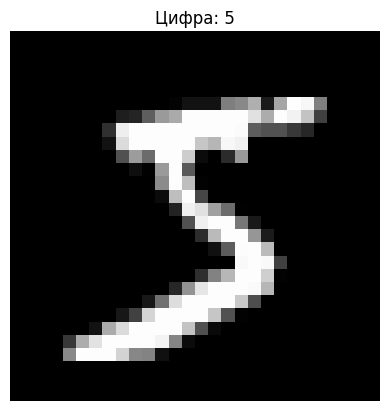

In [62]:
plt.imshow(x_train[0].squeeze(), cmap="grey")
plt.title(f"Цифра: {y_train[0]}")
plt.axis("off")
plt.show()

In [63]:
model_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [64]:
model_cnn.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
model_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("Вход модели:", model_cnn.input_shape)
print("Первый слой:", model_cnn.layers[0].get_config())

x_train: (60000, 28, 28, 1)
x_test: (10000, 28, 28, 1)
Вход модели: (None, 28, 28, 1)
Первый слой: {'name': 'conv2d_14', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'filters': 32, 'kernel_size': (3, 3), 'strides': (1, 1), 'padding': 'valid', 'data_format': 'channels_last', 'dilation_rate': (1, 1), 'groups': 1, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'activity_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None}


In [66]:
history = model_cnn.fit(
    x_train,
    y_train,
    epochs = 5,
    batch_size = 32,
    validation_split = 0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 56s 33ms/step - accuracy: 0.9552 - loss: 0.1473 - val_accuracy: 0.9868 - val_loss: 0.0460
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 52s 31ms/step - accuracy: 0.9856 - loss: 0.0473 - val_accuracy: 0.9887 - val_loss: 0.0345
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 52s 31ms/step - accuracy: 0.9894 - loss: 0.0320 - val_accuracy: 0.9903 - val_loss: 0.0357
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9924 - loss: 0.0233 - val_accuracy: 0.9912 - val_loss: 0.0328
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9939 - loss: 0.0181 - val_accuracy: 0.9905 - val_loss: 0.0323


In [71]:
test_loss, test_accuracy = model_cnn.evaluate(
    x_test,
    y_test
)
print(f"Test accuracy: {test_accuracy:.5f}")
print(f"Test loss: {test_loss:.5f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9912 - loss: 0.0292
Test accuracy: 0.99120
Test loss: 0.02915


In [77]:
y_pred = model_cnn.predict(x_test)
y_pred = y_pred.argmax(axis=1)
errors = np.where(y_pred != y_test)[0]

print("Количество ошибок:", len(errors))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Количество ошибок: 88


Первые 10 ошибок модели



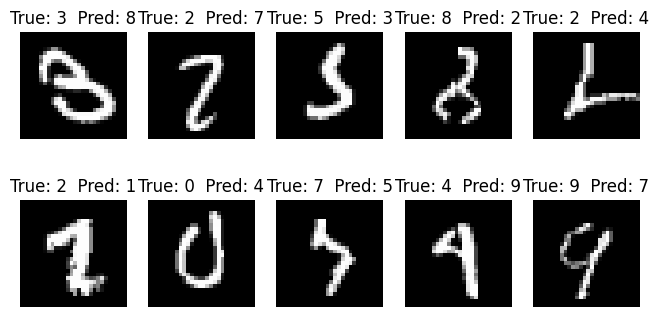

Индекс: 18 | Настоящая цифра: 3 | Предсказание модели: 8
Индекс: 321 | Настоящая цифра: 2 | Предсказание модели: 7
Индекс: 340 | Настоящая цифра: 5 | Предсказание модели: 3
Индекс: 582 | Настоящая цифра: 8 | Предсказание модели: 2
Индекс: 646 | Настоящая цифра: 2 | Предсказание модели: 4
Индекс: 659 | Настоящая цифра: 2 | Предсказание модели: 1
Индекс: 723 | Настоящая цифра: 0 | Предсказание модели: 4
Индекс: 726 | Настоящая цифра: 7 | Предсказание модели: 5
Индекс: 740 | Настоящая цифра: 4 | Предсказание модели: 9
Индекс: 882 | Настоящая цифра: 9 | Предсказание модели: 7


In [79]:
print("Первые 10 ошибок модели")
print()

plt.figure(figsize=(8, 4))
for i,index in enumerate(errors[:10]):
  plt.subplot(2, 5, i + 1)
  plt.imshow(x_test[index].squeeze(), cmap="grey")
  plt.title(f"True: {y_test[index]}  Pred: {y_pred[index]}")
  plt.axis("off")

plt.show()

for ind in errors[0:10]:
  print(
      f"Индекс: {ind} | "
      f"Настоящая цифра: {y_test[ind]} | "
      f"Предсказание модели: {y_pred[ind]}"
  )